<a href="https://colab.research.google.com/github/antoine-jossien/2026_Intro_Python/blob/main/live/part-I/1.8-statistical-foundations-and-ml-practice-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.8-statistical-foundations-and-ml-practice-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

# Practice Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import numpy as `np`, pandas as `pd`, seaborn as `sns`, and the scikit-learn objects you need; seed randomness with `default_rng`, and always evaluate on held-out data.

In [1]:
import numpy as np, pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

## Exercise 1: Explore

Build a DataFrame of 60 stations with `elevation_m` uniform on [200, 3500] and `temp_celsius = 15 - 6.5 * elevation_m/1000 + noise` (noise standard deviation 1.5 °C, seeded). Make a seaborn regression plot of temperature against elevation and print `describe()`.

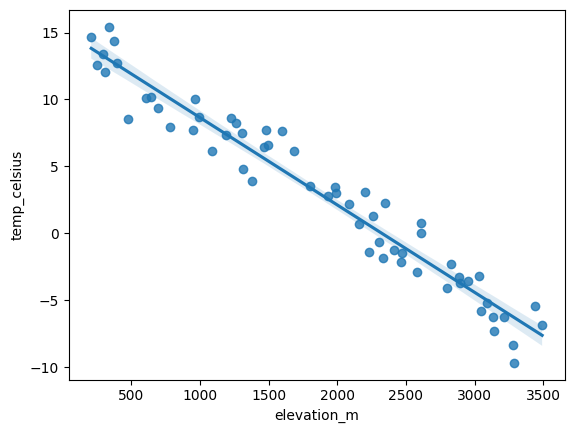

       elevation_m  temp_celsius
count        60.00         60.00
mean       1867.55          2.99
std         987.31          6.63
min         209.04         -9.66
25%        1065.20         -2.44
50%        1990.39          3.03
75%        2655.25          8.03
max        3490.79         15.43


In [2]:
# Your solution here
rng = np.random.default_rng(0)
n = 60
elevation_m = rng.uniform(200, 3500, n)
temp_celsius = 15 - 6.5 * elevation_m/1000 + rng.normal(0, 1.5, n)
df = pd.DataFrame({"elevation_m": elevation_m, "temp_celsius": temp_celsius})

sns.regplot(data=df, x="elevation_m", y="temp_celsius")
plt.show()
print(df.describe().round(2))


## Exercise 2: Correlation

Print the Pearson correlation matrix of the DataFrame and identify the sign of the temperature–elevation correlation.

In [3]:
# Your solution here
print(df.corr().round(3))

              elevation_m  temp_celsius
elevation_m         1.000        -0.973
temp_celsius       -0.973         1.000


## Exercise 3: Fit a linear regression

Fit `LinearRegression` with `X = df[["elevation_m"]]` and `y = df["temp_celsius"]`. Print the recovered lapse rate in °C km⁻¹ and the intercept.

In [4]:
# Your solution here
X = df[["elevation_m"]]      # 2D (doubles crochets)
y = df["temp_celsius"]       # 1D
model = LinearRegression().fit(X, y)
print("lapse rate:", round(model.coef_[0]*1000, 2), "°C/km")
print("intercept:", round(model.intercept_, 2), "°C")

lapse rate: -6.53 °C/km
intercept: 15.18 °C


## Exercise 4: Honest evaluation

Split the data (test size 0.3, fixed random state), fit on the training set, and report the test RMSE and $R^2$.

In [5]:
# Your solution here


from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)
model = LinearRegression().fit(Xtr, ytr)
y_pred = model.predict(Xte)
print("RMSE:", round(root_mean_squared_error(yte, y_pred), 3))
print("R2:  ", round(r2_score(yte, y_pred), 3))

RMSE: 1.35
R2:   0.962


## Exercise 5: A pipeline with scaling

Build a `Pipeline` of `StandardScaler` followed by `LinearRegression`, fit it on the training set, and print its test $R^2$ (via `.score`).

In [6]:
# Your solution here
pipe = make_pipeline(StandardScaler(), LinearRegression())
pipe.fit(Xtr, ytr)
print("pipeline test R2:", round(pipe.score(Xte, yte), 3))

pipeline test R2: 0.962


## Exercise 6: Demonstrate overfitting

Generate 20 noisy points on the lapse rate in kilometres: `x_km = np.linspace(0.2, 3.5, 20)` and `temp_celsius = 15 - 6.5 * x_km + noise`, with noise of standard deviation 2.0 °C from `np.random.default_rng(2)`. Hold out 40 % of the points (`test_size=0.4`, `random_state=0`).

Fit a degree-8 polynomial pipeline (`PolynomialFeatures(degree=8)` followed by `LinearRegression`) on the training part and compare its $R^2$ on the training data with its $R^2$ on the test data. Then fit a plain `LinearRegression` and compare its test $R^2$. Comment on the gap: a degree-8 polynomial has nine parameters and only 12 training points, so it can follow the noise.

In [7]:
# Your solution here
import numpy as np, pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

rng2 = np.random.default_rng(2)
x_km = np.linspace(0.2, 3.5, 20)
temp = 15 - 6.5 * x_km + rng2.normal(0, 2.0, 20)
X_s = x_km.reshape(-1, 1)
Xtr, Xte, ytr, yte = train_test_split(X_s, temp, test_size=0.4, random_state=0)

poly = make_pipeline(PolynomialFeatures(degree=8), LinearRegression()).fit(Xtr, ytr)
lin  = LinearRegression().fit(Xtr, ytr)

print("poly deg 8, train R2:", round(r2_score(ytr, poly.predict(Xtr)), 3))
print("poly deg 8, test  R2:", round(r2_score(yte, poly.predict(Xte)), 3))
print("linear,     test  R2:", round(r2_score(yte, lin.predict(Xte)), 3))

poly deg 8, train R2: 0.953
poly deg 8, test  R2: -111.514
linear,     test  R2: 0.96


## Going deeper (optional)

### Exercise 7: Cross-validation

Cross-validation is covered in the going-deeper box on cross-validation in 1.8. Use `cross_val_score` with 5 folds to estimate the $R^2$ of a plain `LinearRegression` on the full dataset, and print the mean and standard deviation across folds.

In [ ]:
# Your solution here